# Differential geometry 5: Christoffel symbols and parallel transport

*Learning path: differential geometry, part 5 of 7.* [Index](README.md) · Previous: [Gaussian curvature](04-gaussian-curvature.ipynb) · Next: [Geodesics](06-geodesics.ipynb)

On a curved surface there is no obvious way to say that two arrows at different points are "parallel". This notebook
introduces the tool that fixes that, the **Christoffel symbols**, and uses it to move a vector along a path without
turning it: **parallel transport**. You will learn

* what the Christoffel symbols $\Gamma^a{}_{bc}$ are and how they are computed from the metric,
* how to parallel transport a vector along a curve,
* that on a curved surface a vector carried around a loop comes back rotated, by an angle equal to the enclosed
  curvature,
* why a Foucault pendulum turns.

## 1. Why coordinates turn

In polar coordinates the basis directions $\hat r$ and $\hat\phi$ change from point to point, even though the plane
is flat. The Christoffel symbols record how: moving in direction $c$ changes the basis vector $b$ by
$\Gamma^a{}_{bc}$ in direction $a$.

In [1]:
p = metric.generate(polar)
christoffel(p)

$$ds^2 = dr^2 + r^{2}\, d\phi^2$$

> `metric.generate` (see `metric`): A metric with the given coordinates and components g_ab.

**Christoffel symbols of the second kind** (coordinates $r$, $\phi$)

$$\begin{aligned}
\Gamma{}^{r}{}_{\phi}{}_{\phi} &= -r \\
\Gamma{}^{\phi}{}_{r}{}_{\phi} &= \frac{1}{r}
\end{aligned}$$

> `christoffel`: Christoffel symbols of the second kind Gamma^a_bc (christoffelsecond is the same), or of the first kind Gamma_abc.

They come from derivatives of the metric [1][3]:

$$\Gamma^a{}_{bc} = \tfrac12\, g^{ad}\left(\partial_b g_{dc} + \partial_c g_{db} - \partial_d g_{bc}\right)$$

For example $\Gamma^r{}_{\phi\phi} = -\tfrac12\,g^{rr}\,\partial_r g_{\phi\phi} = -\tfrac12\,\partial_r (r^2)$:

In [2]:
simplify(-1/2*deriv(r^2, r))

-r

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

On the sphere of radius $r$:

In [3]:
g = metric.generate(two-sphere)
christoffel(g)

$$ds^2 = r^{2}\, d\theta^2 + r^{2} \, \sin^{2}\left(\theta\right)\, d\phi^2$$

> `metric.generate` (see `metric`): A metric with the given coordinates and components g_ab.

**Christoffel symbols of the second kind** (coordinates $\theta$, $\phi$)

$$\begin{aligned}
\Gamma{}^{\theta}{}_{\phi}{}_{\phi} &= -\sin\left(\theta\right) \, \cos\left(\theta\right) \\
\Gamma{}^{\phi}{}_{\theta}{}_{\phi} &= \frac{\cos\left(\theta\right)}{\sin\left(\theta\right)}
\end{aligned}$$

> `christoffel`: Christoffel symbols of the second kind Gamma^a_bc (christoffelsecond is the same), or of the first kind Gamma_abc.

## 2. Parallel transport

To carry a vector $V^a$ along a curve $x^a(t)$ without turning it [2], its components must change only to compensate for
the turning of the coordinates:

$$\frac{dV^a}{dt} + \Gamma^a{}_{bc}\,V^b\,\frac{dx^c}{dt} = 0$$

In the flat plane this keeps an arrow pointing in a fixed direction. On a sphere it is more interesting.

### Around a circle of latitude

Walk once around the circle $\theta = \theta_0$ on the unit sphere, using $\phi$ as the parameter. Only
$dx^\phi/d\phi = 1$ is non-zero, so with $V = (A, B)$ in the $(\theta, \phi)$ components, the two Christoffel symbols
above give

$$\frac{dA}{d\phi} = \sin\theta_0\cos\theta_0\; B, \qquad \frac{dB}{d\phi} = -\frac{\cos\theta_0}{\sin\theta_0}\; A$$

Start at latitude 30° north ($\theta_0 = \pi/3$) with the vector pointing south ($A = 1$, $B = 0$), and go once around.
`odesolve` integrates differential equations numerically. Its arguments are: the right-hand sides
`[sin(th)*cos(th)*B, -cos(th)/sin(th)*A]` (that is, $dA/d\phi$ and $dB/d\phi$); the unknowns `[A B]` in the same order;
the independent variable `phi`; the start values `[1 0]`; and where to start and stop, `0, 2*pi`. It returns $A$ and
$B$ at the end:

In [4]:
clear
th = pi/3;
odesolve([sin(th)*cos(th)*B, -cos(th)/sin(th)*A], [A B], phi, [1 0], 0, 2*pi)

[-1.0000000000000009, -9.473067404293378e-15]

> `odesolve`: Solves the system of first-order equations dy/dt = rhs numerically (Runge-Kutta) from t = t0 to t = t1 and returns the unknowns at t1: a number for one unknown, a row otherwise.

The vector comes back pointing **north**: $A = -1$. It was never turned along the way, yet after one loop it is
reversed. The solution is $A = \cos(\phi\cos\theta_0)$, so the vector turns relative to the coordinate grid at rate
$\cos\theta_0$. `odeplot` takes the same arguments plus one more, what to draw: `[phi A]` puts the angle $\phi$ on
the horizontal axis and the component $A$ on the vertical one. Here are both components along the way:

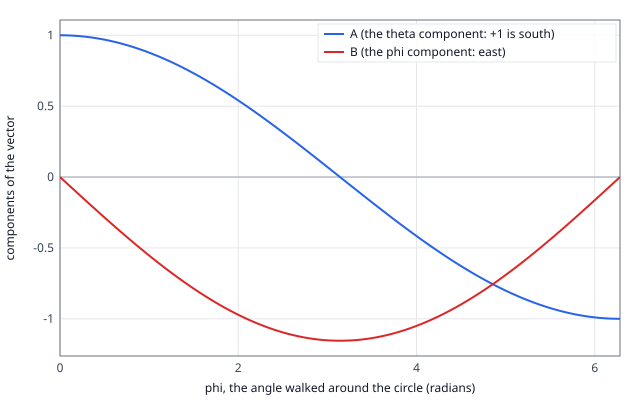

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
pa = odeplot([sin(th)*cos(th)*B, -cos(th)/sin(th)*A], [A B], phi, [1 0], 0, 2*pi, [phi A]);
pb = odeplot([sin(th)*cos(th)*B, -cos(th)/sin(th)*A], [A B], phi, [1 0], 0, 2*pi, [phi B]);
labels(legend(show(pa, pb), "A (the theta component: +1 is south)", "B (the phi component: east)"), "phi, the angle walked around the circle (radians)", "components of the vector")

### Seeing it in 3D

Here is the transported vector drawn as a ribbon above the sphere: at each point of the circle, the ribbon edge shows
where the vector points. Where the ribbon starts and ends (at the front), the arrow has flipped.

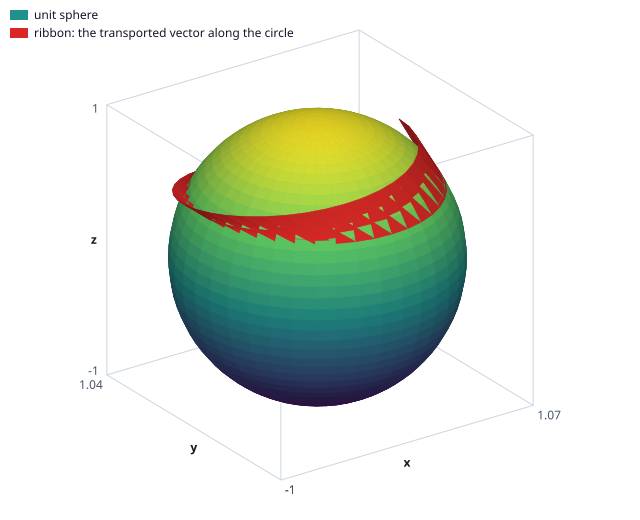

> `legend`: A copy of plot p with new names for its curves in the legend.

In [6]:
r = 1;
w = cos(th);
ball = surface(sin(theta)*cos(phi), sin(theta)*sin(phi), cos(theta), theta, 0, pi, phi, 0, 2*pi);
ribbon = surface(sin(th)*cos(phi) + q*(cos(w*phi)*cos(th)*cos(phi) + sin(w*phi)*sin(phi)), sin(th)*sin(phi) + q*(cos(w*phi)*cos(th)*sin(phi) - sin(w*phi)*cos(phi)), cos(th) - q*cos(w*phi)*sin(th), phi, 0, 2*pi, q, 0, 0.4);
legend(show(ball, ribbon), "unit sphere", "ribbon: the transported vector along the circle")

## 3. Holonomy: the rotation equals the curvature inside

Measured against the direction the walker is facing, the vector turns by $2\pi(1 - \cos\theta_0)$ in one loop. That
is exactly the area of the polar cap inside the circle, $\iint K\,dA = 2\pi(1 - \cos\theta_0)$ on the unit sphere. This
is true in general: the rotation after a small loop equals the curvature enclosed [3]. That is another way to *measure*
curvature from inside, and it leads to the Riemann tensor of part 7.

For $\theta_0 = \pi/3$ the cap has area $\pi$, which is the half turn we found:

In [7]:
eval(2*pi*(1 - cos(th)))

3.141592653589793

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

## 4. The Foucault pendulum

A pendulum swings in a fixed plane, so over a day the Earth carries its swing direction around a circle of latitude
$\lambda$ by parallel transport. After one day the swing has turned by $2\pi\sin\lambda$ (since $\cos\theta_0 = \sin\lambda$).
In the Panthéon in Paris, latitude 48.85°, a full turn of the swing plane takes, in hours:

In [8]:
eval(24/sin(48.85*pi/180))

31.87295705707877

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

About 32 hours, as Foucault showed in 1851 [4]. At the North Pole it would be 24 hours, at the equator the plane never
turns.

## Summary

* Christoffel symbols $\Gamma^a{}_{bc}$ describe how the coordinate directions turn; `christoffel(g)` computes them.
* Parallel transport moves a vector without turning it: $\dot V^a + \Gamma^a{}_{bc}V^b\dot x^c = 0$.
* Around a loop on a curved surface, the vector comes back rotated by the enclosed curvature.

**Try it:** change `th` to `pi/4` or `1.4` and re-run. Near the equator, how much does the vector turn?

Next: [Geodesics](06-geodesics.ipynb), the curves that parallel transport their own velocity: the straightest possible
lines.

## Sources

Numbers in square brackets in the text refer to this list.

1. E. B. Christoffel, "Ueber die Transformation der homogenen Differentialausdrücke zweiten Grades", *Journal für die reine und angewandte Mathematik* **70**, 46–70 (1869). [doi:10.1515/crll.1869.70.46](https://doi.org/10.1515/crll.1869.70.46)
2. T. Levi-Civita, "Nozione di parallelismo in una varietà qualunque", *Rendiconti del Circolo Matematico di Palermo* **42**, 173–204 (1917). [doi:10.1007/BF03014898](https://doi.org/10.1007/BF03014898)
3. M. P. do Carmo, *Differential Geometry of Curves and Surfaces*, 2nd ed., Dover (2016). Sections 4-4 (parallel transport) and 4-5 (holonomy and Gauss–Bonnet).
4. L. Foucault, "Démonstration physique du mouvement de rotation de la Terre au moyen du pendule", *Comptes rendus de l'Académie des sciences* **32**, 135–138 (1851).